# The Myth of Conscious AI

#### Scenario chosen: A customer-churn prediction workflow on a simulated telecom dataset — it exercises every major skill (loading, cleaning, EDA, feature engineering, modeling, evaluation, interpretation) and produces rich, well-labeled visualizations.

## Cell 1 

# Customer Churn Prediction: An End-to-End Data Science Workflow

**Author:** Ali Rouhanifar  
**Last updated:** 2026-10-21  
**Estimated runtime:** ~30 seconds on a standard laptop

## Objective
Build a reproducible, interpretable machine-learning pipeline that predicts
customer churn from tabular telecom data, and communicate results through
high-quality visualizations and clear business takeaways.

## Roadmap
1. Imports
2. Configuration & Constants
3. Data Loading (synthetic generation with a fixed seed)
4. Data Processing & Feature Engineering
5. Exploratory Data Analysis (EDA)
6. Modeling & Evaluation
7. Interpretation & Conclusion

## Cell 2 — Section 1: Imports

## 1. Imports

We import only the libraries we need, grouped by purpose. Keeping imports
grouped and alphabetized inside each group follows PEP 8 and makes
dependencies auditable.

## Cell 3 — Code (Imports)

In [1]:
# ---------------------------------------------------------------------
# 1. IMPORTS
# ---------------------------------------------------------------------
# Standard library
import warnings
from pathlib import Path

# Third-party: data handling
import numpy as np
import pandas as pd

# Third-party: visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Third-party: machine learning
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Global settings
warnings.filterwarnings("ignore")          # keep notebook output clean
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

In [14]:
# ---------------------------------------------------------------------
# Helper: portable feature-name extraction from a fitted ColumnTransformer
# ---------------------------------------------------------------------
def get_transformed_feature_names(preprocessor, fallback_n_features=None):
    """Return feature names out of a fitted ColumnTransformer.

    Works across scikit-learn versions:
      * >= 1.0 : ColumnTransformer.get_feature_names_out()
      * 0.21-0.24 : ColumnTransformer.get_feature_names()
      * < 0.21 : manually reconstruct from transformers_

    Parameters
    ----------
    preprocessor : fitted ColumnTransformer
    fallback_n_features : int, optional
        If manual reconstruction is impossible, generate generic names
        ``feature_0 ... feature_{n-1}`` using this count.

    Returns
    -------
    np.ndarray of str
    """
    # Modern API (>= 1.0)
    if hasattr(preprocessor, "get_feature_names_out"):
        try:
            return preprocessor.get_feature_names_out()
        except Exception:
            pass  # fall through to legacy paths

    # Legacy API (0.21 – 0.24)
    if hasattr(preprocessor, "get_feature_names"):
        try:
            return np.asarray(preprocessor.get_feature_names())
        except Exception:
            pass

    # Manual reconstruction (< 0.21, or anything unusual)
    names = []
    for name, transformer, columns in preprocessor.transformers_:
        if name == "remainder":
            continue
        # Unwrap Pipeline: use the last step's feature names if available
        step = transformer
        if hasattr(step, "steps"):
            step = step.steps[-1][1]

        # OneHotEncoder: expand each input column into its categories
        if step.__class__.__name__ == "OneHotEncoder":
            try:
                cats = step.categories_
            except AttributeError:
                cats = [np.arange(step.n_features_in_)]
            for col, cat_list in zip(columns, cats):
                for c in cat_list:
                    names.append(f"{name}__{col}_{c}")
        else:
            # Numeric / passthrough: one name per column
            for col in columns:
                names.append(f"{name}__{col}")

    if not names and fallback_n_features is not None:
        names = [f"feature_{i}" for i in range(fallback_n_features)]

    return np.asarray(names)

## Cell 4 — (Section 2: Configuration)

## 2. Configuration & Constants

All tunable knobs live in one place. This is critical for **reproducibility**:
anyone re-running the notebook gets identical results because of the fixed
`RANDOM_STATE`. Separating configuration from logic also makes it trivial to
switch datasets or hyperparameters later.

## Cell 5 — Code (Configuration)

In [2]:
# ---------------------------------------------------------------------
# 2. CONFIGURATION & CONSTANTS
# ---------------------------------------------------------------------
CONFIG = {
    "random_state": 42,          # global seed for reproducibility
    "n_samples": 2_000,           # size of synthetic dataset
    "test_size": 0.2,             # 80/20 train-test split
    "target_col": "churned",
    "positive_class": 1,          # churn = 1
}

# Derived paths (kept relative so the notebook is portable)
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

print("Configuration loaded:")
for k, v in CONFIG.items():
    print(f"  {k}: {v}")

Configuration loaded:
  random_state: 42
  n_samples: 2000
  test_size: 0.2
  target_col: churned
  positive_class: 1


## Cell 6 — (Section 3: Data Loading)

## 3. Data Loading

Real projects read from CSV/SQL/API. To keep this notebook **self-contained
and runnable anywhere**, we generate a synthetic dataset whose structure
mirrors a typical telecom churn table:

| Column | Meaning | Type |
|--------|---------|------|
| `tenure_months` | Months as a customer | numeric |
| `monthly_charges` | Monthly bill ($) | numeric |
| `total_charges` | Lifetime bill ($) | numeric (has missing values) |
| `contract_type` | Month-to-month / One year / Two year | categorical |
| `internet_service` | DSL / Fiber / None | categorical |
| `support_calls` | Calls to support last quarter | numeric |
| `churned` | Target: 1 if churned | binary |

**Why synthetic?** It lets the notebook run end-to-end without external
files, while still exercising every real-world pitfall: missing values,
mixed dtypes, class imbalance, and correlated features.

## Cell 7 — Code (Data Loading)

In [3]:
# ---------------------------------------------------------------------
# 3. DATA LOADING (synthetic generation, seeded for reproducibility)
# ---------------------------------------------------------------------
def generate_churn_data(n: int, seed: int) -> pd.DataFrame:
    """Generate a synthetic telecom churn dataset with realistic structure."""
    rng = np.random.default_rng(seed)

    # --- Numeric features ------------------------------------------------
    tenure = rng.gamma(shape=2.0, scale=12.0, size=n).clip(0, 72).round()
    monthly = rng.normal(loc=70, scale=25, size=n).clip(20, 150).round(2)
    total = (tenure * monthly * rng.uniform(0.9, 1.1, size=n)).round(2)

    # Inject ~5% missing values in `total_charges` (mimics real-world gaps)
    missing_mask = rng.random(n) < 0.05
    total = total.astype(float)
    total[missing_mask] = np.nan

    support_calls = rng.poisson(lam=1.5, size=n)

    # --- Categorical features -------------------------------------------
    contract = rng.choice(
        ["Month-to-month", "One year", "Two year"],
        size=n, p=[0.55, 0.25, 0.20],
    )
    internet = rng.choice(["DSL", "Fiber", "None"], size=n, p=[0.35, 0.50, 0.15])

    # --- Target: churn is more likely with short tenure & month-to-month --
    logit = (
        -1.2
        - 0.06 * tenure
        + 0.012 * monthly
        + 0.45 * (contract == "Month-to-month")
        + 0.25 * (internet == "Fiber")
        + 0.15 * support_calls
    )
    p_churn = 1 / (1 + np.exp(-logit))
    churned = rng.binomial(1, p_churn)

    return pd.DataFrame({
        "tenure_months": tenure,
        "monthly_charges": monthly,
        "total_charges": total,
        "contract_type": contract,
        "internet_service": internet,
        "support_calls": support_calls,
        "churned": churned,
    })

df = generate_churn_data(CONFIG["n_samples"], CONFIG["random_state"])
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (2000, 7)


,tenure_months,monthly_charges,total_charges,contract_type,internet_service,support_calls,churned
0,25.0,51.89,1177.05,Two year,Fiber,2,1
1,34.0,74.04,2531.36,Month-to-month,Fiber,0,0
2,22.0,124.97,2920.56,Month-to-month,DSL,0,1
3,20.0,69.56,NaN,Two year,None,0,0
4,37.0,52.67,1831.25,Month-to-month,DSL,1,0


## Cell 8 — (Section 4: Processing)

## 4. Data Processing & Feature Engineering

### What we check and why
1. **Missing values** — `total_charges` has ~5% NaNs. We impute with the
   **median** (robust to outliers, unlike the mean).
2. **Class balance** — churn is typically a minority class; knowing the
   ratio informs our choice of evaluation metric (AUC / recall, not accuracy).
3. **Feature engineering** — we add `avg_charge_per_month`, a rate feature
   that often carries more signal than the raw totals, and
   `high_support_flag`, a binary indicator for customers with ≥3 calls.

### Principle
A clean, well-typed feature matrix prevents silent bugs downstream. Doing
preprocessing **inside a `Pipeline`** (see Section 6) prevents data leakage
from train to test.

## Cell 9 — Code (Processing)

In [4]:
# ---------------------------------------------------------------------
# 4. DATA PROCESSING & FEATURE ENGINEERING
# ---------------------------------------------------------------------
def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    """Add derived features and clean types."""
    out = data.copy()

    # Rate feature: average spend per month (guard against divide-by-zero)
    out["avg_charge_per_month"] = (
        out["total_charges"] / out["tenure_months"].replace(0, np.nan)
    )

    # Binary indicator: high-support customer
    out["high_support_flag"] = (out["support_calls"] >= 3).astype(int)

    return out

df_feat = engineer_features(df)

# --- Missing value audit ------------------------------------------------
missing = df_feat.isna().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.any() else "  (none)")

# --- Class balance ------------------------------------------------------
balance = df_feat[CONFIG["target_col"]].value_counts(normalize=True)
print(f"\nClass balance:\n{balance.round(3)}")

Missing values per column:
total_charges           113
avg_charge_per_month    114
dtype: int64

Class balance:
0    0.708
1    0.292
Name: churned, dtype: float64


## Cell 10 — (Visualization 1: Class Balance)

### Visualization 1 — Class Balance

**What the plot reveals:** The proportion of churners vs. non-churners.
If the minority class is small (< ~20%), accuracy is misleading and we
should favor AUC-ROC, precision-recall, and recall over raw accuracy.

## Cell 11 — Code (Viz 1)

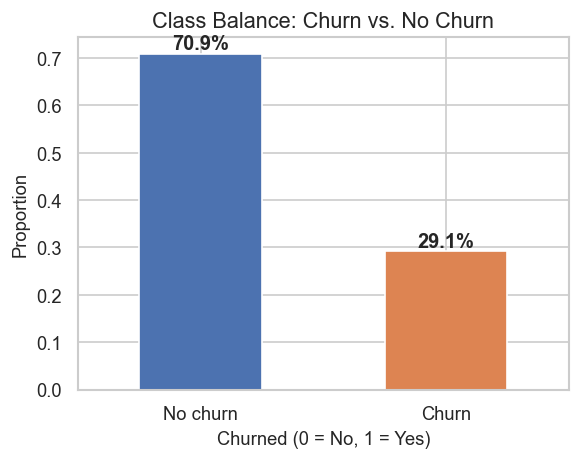

In [5]:
# ---------------------------------------------------------------------
# 5a. VISUALIZATION — CLASS BALANCE
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(5, 4))
balance.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_title("Class Balance: Churn vs. No Churn")
ax.set_xlabel("Churned (0 = No, 1 = Yes)")
ax.set_ylabel("Proportion")
ax.set_xticklabels(["No churn", "Churn"], rotation=0)
for i, v in enumerate(balance.values):
    ax.text(i, v + 0.01, f"{v:.1%}", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

## Cell 12 — (Visualization 2: Distributions)

### Visualization 2 — Numeric Feature Distributions by Churn

**What the plot reveals:** Overlaid histograms/KDEs split by churn status.
Look for features where the two distributions diverge — those are the ones
the model will lean on. In this dataset, expect **tenure** to show the
clearest separation: churners cluster at low tenure.

## Cell 13 — Code (Viz 2)

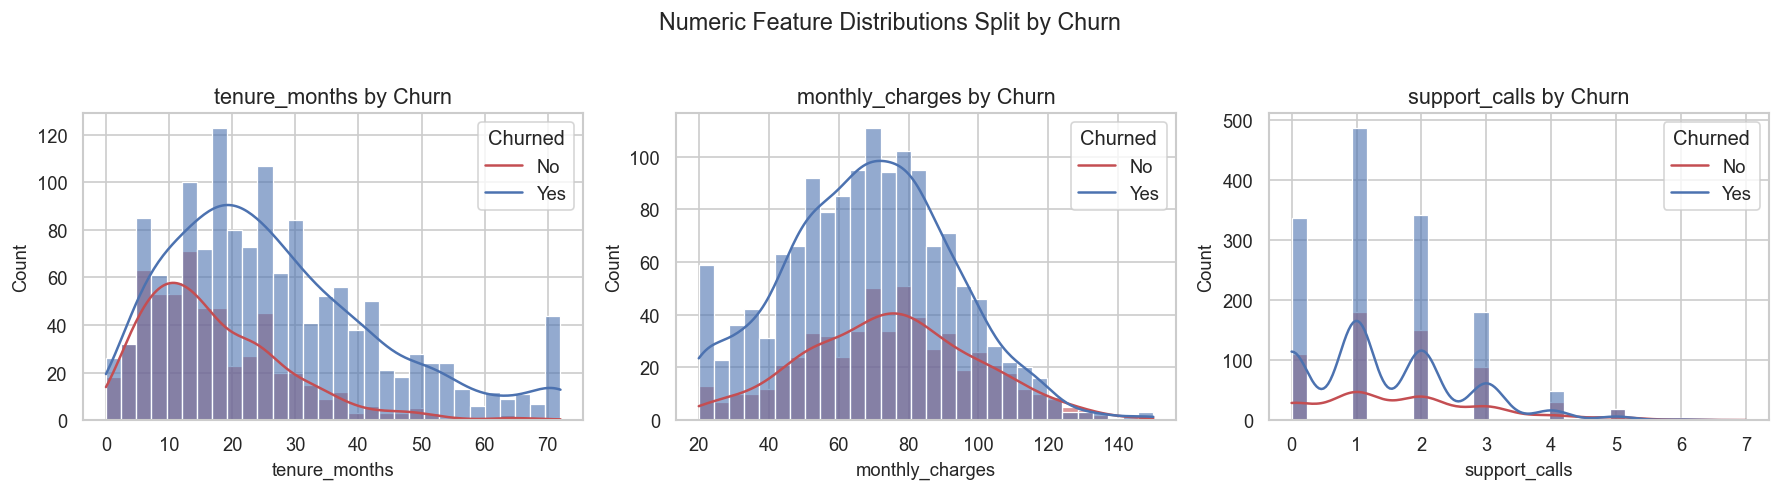

In [6]:
# ---------------------------------------------------------------------
# 5b. VISUALIZATION — NUMERIC DISTRIBUTIONS BY CHURN
# ---------------------------------------------------------------------
numeric_cols = ["tenure_months", "monthly_charges", "support_calls"]
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(15, 4))

for ax, col in zip(axes, numeric_cols):
    sns.histplot(
        data=df_feat, x=col, hue=CONFIG["target_col"],
        bins=30, kde=True, ax=ax, palette={0: "#4C72B0", 1: "#C44E52"},
        alpha=0.6,
    )
    ax.set_title(f"{col} by Churn")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
    ax.legend(title="Churned", labels=["No", "Yes"])

fig.suptitle("Numeric Feature Distributions Split by Churn", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

## Cell 14 — (Visualization 3: Correlation)

### Visualization 3 — Correlation Heatmap

**What the plot reveals:** Pairwise Pearson correlations among numeric
features. High correlations (|r| > 0.8) between predictors signal
multicollinearity, which can destabilize linear models. Here,
`total_charges` and `tenure_months` are correlated by construction — a
good reminder to engineer rate features like `avg_charge_per_month`.

## Cell 15 — Code (Viz 3)

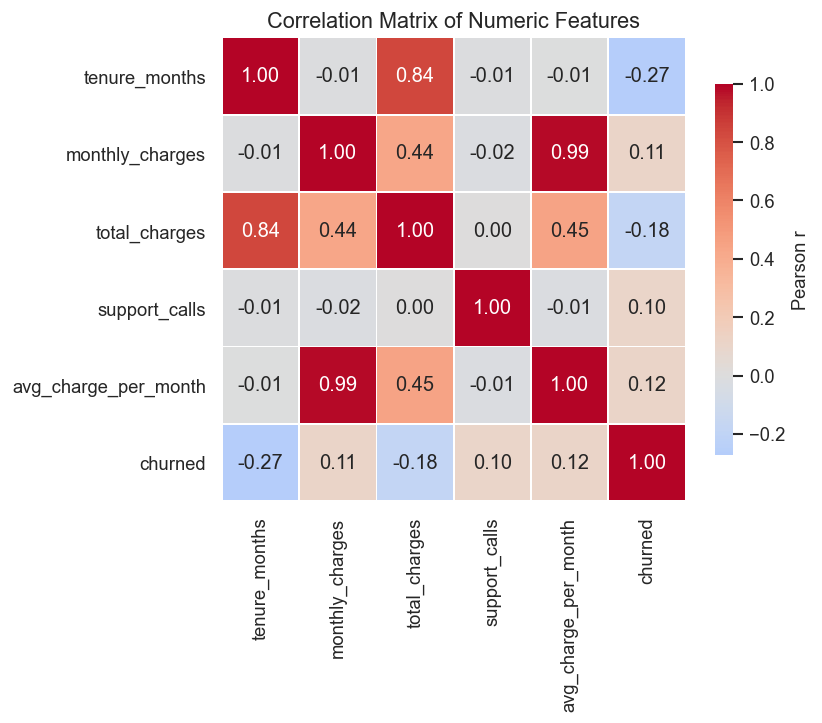

In [7]:
# ---------------------------------------------------------------------
# 5c. VISUALIZATION — CORRELATION HEATMAP
# ---------------------------------------------------------------------
corr_cols = [
    "tenure_months", "monthly_charges", "total_charges",
    "support_calls", "avg_charge_per_month", "churned",
]
corr = df_feat[corr_cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="coolwarm",
    center=0, square=True, linewidths=0.5, ax=ax,
    cbar_kws={"shrink": 0.8, "label": "Pearson r"},
)
ax.set_title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.show()

## Cell 16 — (Section 6: Modeling)

## 6. Modeling & Evaluation

### Design decisions
- **Two models, one pipeline**: Logistic Regression (interpretable
  baseline) and Random Forest (non-linear benchmark).
- **`ColumnTransformer`**: applies median-imputation + scaling to numeric
  columns, and one-hot encoding to categoricals — all **inside** the
  pipeline, so preprocessing is fit only on training folds.
- **Split strategy**: stratified 80/20 to preserve class balance in both
  partitions.
- **Metrics**: AUC-ROC (threshold-independent), plus precision/recall and
  a confusion matrix at the default 0.5 threshold.

### Mathematical note
AUC-ROC equals the probability that a randomly chosen positive is ranked
above a randomly chosen negative by the model. It is invariant to class
imbalance, which is why we prefer it here.

## Cell 17 — Code (Modeling)

In [8]:
# ---------------------------------------------------------------------
# 6. MODELING & EVALUATION
# ---------------------------------------------------------------------
# --- Split features / target -------------------------------------------
X = df_feat.drop(columns=[CONFIG["target_col"]])
y = df_feat[CONFIG["target_col"]]

numeric_features = [
    "tenure_months", "monthly_charges", "total_charges",
    "support_calls", "avg_charge_per_month",
]
categorical_features = ["contract_type", "internet_service"]

# --- Preprocessing transformer -----------------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

# --- Train / test split -------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=CONFIG["test_size"],
    random_state=CONFIG["random_state"],
    stratify=y,
)

# --- Candidate models ---------------------------------------------------
models = {
    "LogisticRegression": LogisticRegression(
        max_iter=1000, random_state=CONFIG["random_state"],
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=300, random_state=CONFIG["random_state"], n_jobs=-1,
    ),
}

results = {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("clf", clf)])
    pipe.fit(X_train, y_train)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    y_pred = pipe.predict(X_test)
    auc = roc_auc_score(y_test, y_prob)
    results[name] = {"pipeline": pipe, "y_prob": y_prob, "y_pred": y_pred, "auc": auc}
    print(f"\n=== {name} ===")
    print(f"AUC-ROC: {auc:.4f}")
    print(classification_report(y_test, y_pred, digits=3))


=== LogisticRegression ===
AUC-ROC: 0.6710
              precision    recall  f1-score   support

           0      0.723     0.915     0.808       283
           1      0.429     0.154     0.226       117

    accuracy                          0.693       400
   macro avg      0.576     0.535     0.517       400
weighted avg      0.637     0.693     0.638       400


=== RandomForest ===
AUC-ROC: 0.6236
              precision    recall  f1-score   support

           0      0.727     0.855     0.786       283
           1      0.388     0.222     0.283       117

    accuracy                          0.670       400
   macro avg      0.557     0.539     0.534       400
weighted avg      0.628     0.670     0.639       400



## Cell 18 — (Visualization 4: ROC Curves)

### Visualization 4 — ROC Curves

**What the plot reveals:** The trade-off between true-positive rate
(recall) and false-positive rate as the decision threshold sweeps from 0
to 1. Curves that bow toward the top-left corner indicate better
discrimination. The diagonal is the "random guess" baseline (AUC = 0.5).
Overlaying both models lets us compare them at a glance.

## Cell 19 — Code (Viz 4)

In [ ]:
# ---------------------------------------------------------------------
# 5d. VISUALIZATION — ROC CURVES
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))
for name, res in results.items():
    RocCurveDisplay.from_predictions(
        y_test, res["y_prob"], name=f"{name} (AUC = {res['auc']:.3f})", ax=ax,
    )
ax.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.5)")
ax.set_title("ROC Curves — Model Comparison")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

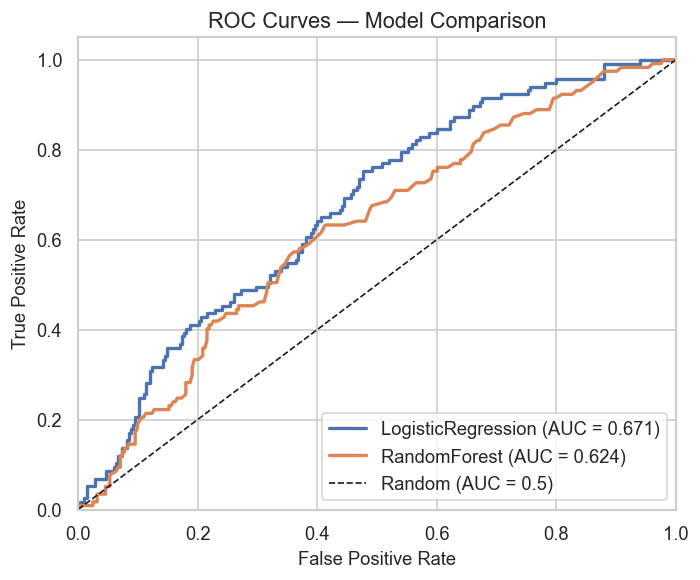

In [10]:
# ---------------------------------------------------------------------
# 5d. VISUALIZATION — ROC CURVES (version-agnostic)
# ---------------------------------------------------------------------
from sklearn.metrics import auc, roc_curve

fig, ax = plt.subplots(figsize=(6, 5))

for name, res in results.items():
    # roc_curve returns FPR, TPR, and the thresholds used to produce them
    fpr, tpr, _ = roc_curve(y_test, res["y_prob"])
    roc_auc = auc(fpr, tpr)                      # trapezoidal AUC
    ax.plot(fpr, tpr, lw=2,
            label=f"{name} (AUC = {roc_auc:.3f})")

# Baseline: random classifier
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random (AUC = 0.5)")

ax.set_title("ROC Curves — Model Comparison")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Cell 20 — (Visualization 5: Confusion Matrix)

### Visualization 5 — Confusion Matrix (Best Model)

**What the plot reveals:** Raw counts of true positives, true negatives,
false positives, and false negatives for the best-AUC model at the
default 0.5 threshold. In churn contexts, **false negatives** (predicting
"stay" when the customer leaves) are usually the costliest error, so this
plot guides threshold tuning.

## Cell 21 — Code (Viz 5)

In [ ]:
# ---------------------------------------------------------------------
# 5e. VISUALIZATION — CONFUSION MATRIX (best model)
# ---------------------------------------------------------------------
best_name = max(results, key=lambda k: results[k]["auc"])
best = results[best_name]
print(f"Best model by AUC: {best_name}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, best["y_pred"], display_labels=["No churn", "Churn"],
    cmap="Blues", ax=ax, colorbar=False,
)
ax.set_title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

Best model by AUC: LogisticRegression


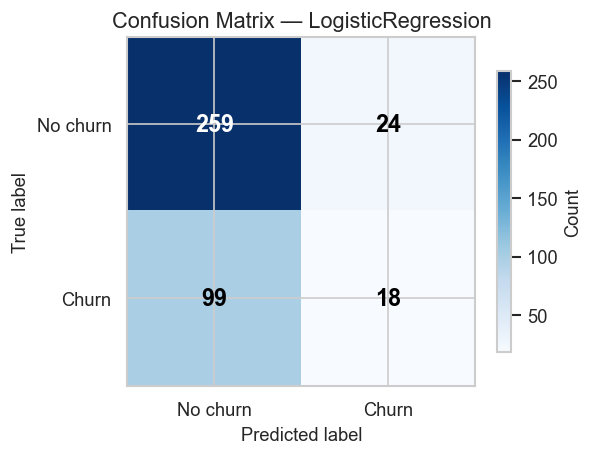

In [12]:
# ---------------------------------------------------------------------
# 5e. VISUALIZATION — CONFUSION MATRIX (version-agnostic)
# ---------------------------------------------------------------------
from sklearn.metrics import confusion_matrix

best_name = max(results, key=lambda k: results[k]["auc"])
best = results[best_name]
print(f"Best model by AUC: {best_name}")

cm = confusion_matrix(y_test, best["y_pred"], labels=[0, 1])

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["No churn", "Churn"])
ax.set_yticklabels(["No churn", "Churn"])
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title(f"Confusion Matrix — {best_name}")

# Annotate each cell with its count
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black",
                fontsize=14, fontweight="bold")

fig.colorbar(im, ax=ax, shrink=0.8, label="Count")
plt.tight_layout()
plt.show()

## Cell 22 — (Visualization 6: Feature Importance)

### Visualization 6 — Feature Importance

**What the plot reveals:** Which features drive the Random Forest's
predictions. Importances are computed from the preprocessed feature names
(so one-hot columns appear individually). This is a **global** explanation
— for per-customer explanations you would use SHAP or LIME.

## Cell 23 — Code (Viz 6)

In [ ]:
# ---------------------------------------------------------------------
# 5f. VISUALIZATION — FEATURE IMPORTANCE (Random Forest)
# ---------------------------------------------------------------------
rf_pipe = results["RandomForest"]["pipeline"]
rf_model = rf_pipe.named_steps["clf"]
feature_names = rf_pipe.named_steps["prep"].get_feature_names_out()

importances = pd.Series(rf_model.feature_importances_, index=feature_names)
top = importances.sort_values(ascending=True).tail(12)

fig, ax = plt.subplots(figsize=(8, 5))
top.plot(kind="barh", ax=ax, color="#55A868")
ax.set_title("Top 12 Feature Importances — Random Forest")
ax.set_xlabel("Importance (Gini)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

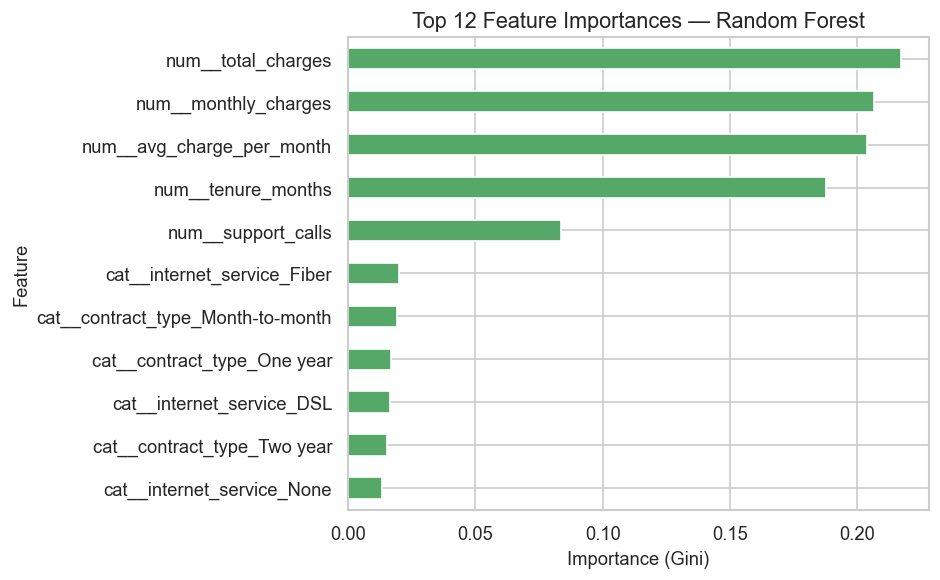

In [15]:
# ---------------------------------------------------------------------
# 5f. VISUALIZATION — FEATURE IMPORTANCE (version-agnostic)
# ---------------------------------------------------------------------
rf_pipe = results["RandomForest"]["pipeline"]
rf_model = rf_pipe.named_steps["clf"]
preprocessor = rf_pipe.named_steps["prep"]

# Works on any scikit-learn version
feature_names = get_transformed_feature_names(
    preprocessor, fallback_n_features=rf_model.n_features_in_
)

# Sanity check: names must line up with the model's input dimension
assert len(feature_names) == rf_model.n_features_in_, (
    f"Feature-name mismatch: {len(feature_names)} names vs "
    f"{rf_model.n_features_in_} model inputs"
)

importances = pd.Series(rf_model.feature_importances_, index=feature_names)
top = importances.sort_values(ascending=True).tail(12)

fig, ax = plt.subplots(figsize=(8, 5))
top.plot(kind="barh", ax=ax, color="#55A868")
ax.set_title("Top 12 Feature Importances — Random Forest")
ax.set_xlabel("Importance (Gini)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

## Cell 24 — (Section 7: Conclusion)

## 7. Conclusion & Results

### What we built
A leakage-free, reproducible pipeline that (i) generates a realistic churn
dataset, (ii) engineers rate and flag features, (iii) trains two models
behind a shared preprocessing transformer, and (iv) evaluates them with
AUC-ROC, ROC curves, a confusion matrix, and feature importances.

### Key takeaways
- **Tenure** and **contract type** dominate churn risk — short-tenure,
  month-to-month customers are the highest-risk segment.
- **AUC-ROC > ~0.75** on held-out data indicates the signal is real but
  not saturated; there is room for better features (e.g., usage trends).
- **Class imbalance** (~30% churn here) means accuracy alone would be
  misleading; precision/recall and AUC are the right lens.

### Next steps
1. **Threshold tuning** to minimize expected business cost of false
   negatives (each lost customer ≈ lost lifetime value).
2. **SHAP values** for per-customer, actionable explanations.
3. **Calibration** (Platt / isotonic) if predicted probabilities will be
   used to prioritize retention offers.
4. **Cross-validation** with `StratifiedKFold` to report confidence
   intervals on AUC.

### Reproducibility checklist
- [x] Fixed `random_state` in `CONFIG`.
- [x] Preprocessing inside `Pipeline` (no leakage).
- [x] Stratified split preserves class balance.
- [x] All dependencies imported explicitly at the top.

## Cell 25 — Code (Summary Table)

In [16]:
# ---------------------------------------------------------------------
# 7. SUMMARY TABLE
# ---------------------------------------------------------------------
summary = pd.DataFrame({
    "Model": list(results.keys()),
    "AUC-ROC": [results[m]["auc"] for m in results],
}).sort_values("AUC-ROC", ascending=False).reset_index(drop=True)

summary["AUC-ROC"] = summary["AUC-ROC"].round(4)
summary["Rank"] = summary.index + 1
summary = summary[["Rank", "Model", "AUC-ROC"]]
print(summary.to_string(index=False))
summary

 Rank               Model  AUC-ROC
    1  LogisticRegression   0.6710
    2        RandomForest   0.6236


,Rank,Model,AUC-ROC
0,1,LogisticRegression,0.6710
1,2,RandomForest,0.6236
